In [1]:
from pathlib import Path
from ase.io import read
from ase import Atoms
from ase.visualize.plot import plot_atoms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from typing import Union
from collections import defaultdict
from tqdm.notebook import tqdm
from scipy.spatial import ConvexHull

In [2]:
root_path = Path('../source_data/simdata/')

## Data aggregation

In [3]:
# Определим функцию для оценки размера НЧ по данным .xyz файлов. Размер будем считать как диаметр сферы, описанной вокруг НЧ.
def get_size(atoms:Atoms)->float:
    ''' 
    Определение размера НЧ, как радиуса описанной окружности вокруг неё.
    '''
    centraited_pos = atoms.positions-atoms.get_center_of_mass()
    r2 = np.einsum('ij,ij->i', centraited_pos, centraited_pos)
    return 2*np.sqrt(r2.max()).round(4)

# Введем также дополнительные метрики оценки отклонения формы НЧ от сферической
def calculate_gyration_asphericity(atoms):
    '''
    Расчет коэффициента асферичности (Delta) через тензор гирации.
    '''
    pos_centered = atoms.positions-atoms.get_center_of_mass()
    
    # Вычисляем тензор гирации (ковариационную матрицу координат)
    N = len(pos_centered)
    gyration_tensor = np.dot(pos_centered.T, pos_centered) / N
    
    # Находим собственные числа тензора гирации и сортируем S1 <= S2 <= S3
    eigenvalues = np.linalg.eigvals(gyration_tensor)
    S1, S2, S3 = np.sort(eigenvalues)
    
    # Защита от деления на ноль для гипотетического одиночного атома
    if (S1 + S2 + S3) == 0:
        return 0.0
    
    # Расчет коэффициента асферичности Дельта
    numerator = (S1 - S2)**2 + (S2 - S3)**2 + (S3 - S1)**2
    denominator = 2 * (S1 + S2 + S3)**2
    delta_asphericity = numerator / denominator
        
    return delta_asphericity.round(4)


def calculate_Wadell_sphericity(atoms):
    '''
    Отношение площадей поверхности сферы тождественного объема и целевого многогранника.
    '''
    positions = atoms.get_positions()
    if len(positions) < 4: 
        return 1.0
        
    # Строим выпуклую оболочку вокруг внешних атомов
    hull = ConvexHull(positions)
    
    V = hull.volume  # Объем многогранника
    A = hull.area    # Площадь поверхности многогранника
    
    psi = (np.pi**(1/3) * (6 * V)**(2/3)) / A
    return np.round(psi, 4)

def plot_shape_asphericity(df, save_path: Union[Path, str] = None):
    plot_df = df.copy()
    
    shape_order = ['sph', 'wulff', 'faced']
    colors = sns.color_palette('muted', 2)
    state_colors = {'Init': colors[0],
                    'Equil': colors[1]
                   }
        
    fig, axes = plt.subplots(3, 2, figsize=(15, 13), sharex='col')
    
    # Глобальные границы по оси X для сопоставимости масштабов
    asph_min = min(plot_df['Init_gyration_asphericity'].min(), plot_df['Equil_gyration_asphericity'].min())
    asph_max = max(plot_df['Init_gyration_asphericity'].max(), plot_df['Equil_gyration_asphericity'].max())
    sph_min = min(plot_df['Init_Wadell_sphericity'].min(), plot_df['Equil_Wadell_sphericity'].min())
    sph_max = max(plot_df['Init_Wadell_sphericity'].max(), plot_df['Equil_Wadell_sphericity'].max())
    
    asph_range = (max(0, asph_min - 0.02), min(1, asph_max + 0.02))
    sph_range = (max(0, sph_min - 0.02), min(1, sph_max + 0.02))
    
    num_bins = 15
    
    asph_bins = np.linspace(asph_range[0], asph_range[1], num_bins + 1)
    sph_bins = np.linspace(sph_range[0], sph_range[1], num_bins + 1)

    # Элементы легенды
    legend_patches = [Patch(color=state_colors['Init'], alpha=0.8, label='Init'),
                      Patch(color=state_colors['Equil'], alpha=0.8, label='Equil')
                     ]

    for row_idx, shape_name in enumerate(shape_order):
        sub_df = plot_df[plot_df['shape'] == shape_name]
        if sub_df.empty:
            continue
            
        total_particles = len(sub_df)
            
        # СТОЛБЕЦ 1: АСФЕРИЧНОСТЬ
        ax_asph = axes[row_idx, 0]
        
        counts_init, _ = np.histogram(sub_df['Init_gyration_asphericity'], bins=asph_bins)
        counts_equil, _ = np.histogram(sub_df['Equil_gyration_asphericity'], bins=asph_bins)
        
        prob_init = counts_init / total_particles
        prob_equil = counts_equil / total_particles
        
        bin_centers = (asph_bins[:-1] + asph_bins[1:]) / 2
        width = (asph_bins[1] - asph_bins[0]) / 2.5  # Оптимальная ширина для двух баров
        
        ax_asph.bar(bin_centers - width/2, prob_init, width=width, color=state_colors['Init'], alpha=0.8)
        ax_asph.bar(bin_centers + width/2, prob_equil, width=width, color=state_colors['Equil'], alpha=0.8)
        
        ax_asph.set_ylabel(f"Форма: {shape_name}\nДоля частиц", fontsize=14)
        ax_asph.legend(handles=legend_patches, loc='upper right', fontsize=10, frameon=True)
        
        if row_idx == 2:
            ax_asph.set_xlabel("Коэффициент асферичности (0 = идеальная сфера)", fontsize=14)
        if row_idx == 0:
            ax_asph.set_title("Асферичность (Тензор гирации)", fontsize=14, fontweight='bold')
        
            
        # СТОЛБЕЦ 2: СФЕРИЧНОСТЬ ВАДЕЛЛА
        ax_sph = axes[row_idx, 1]
        
        counts_init_s, _ = np.histogram(sub_df['Init_Wadell_sphericity'], bins=sph_bins)
        counts_equil_s, _ = np.histogram(sub_df['Equil_Wadell_sphericity'], bins=sph_bins)
        
        prob_init_s = counts_init_s / total_particles
        prob_equil_s = counts_equil_s / total_particles
        
        bin_centers_s = (sph_bins[:-1] + sph_bins[1:]) / 2
        width_s = (sph_bins[1] - sph_bins[0]) / 2.5
        
        ax_sph.bar(bin_centers_s - width_s/2, prob_init_s, width=width_s, color=state_colors['Init'], alpha=0.8)
        ax_sph.bar(bin_centers_s + width_s/2, prob_equil_s, width=width_s, color=state_colors['Equil'], alpha=0.8)
        
        ax_sph.set_ylabel("Доля частиц", fontsize=14)
        ax_sph.legend(handles=legend_patches, loc='upper left', fontsize=10, frameon=True)
        
        if row_idx == 2:
            ax_sph.set_xlabel("Индекс сферичности Ваделла (1 = идеальная сфера)", fontsize=14)
        if row_idx == 0:
            ax_sph.set_title("Сферичность Ваделла", fontsize=14, fontweight='bold')

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')

    plt.show()

In [4]:
# Соберем данные из csv файлов (результаты анализа RDF для НЧ приведенных в равновесие с термостатом)
# и дополним их оценкой размеров "вырезанных" из фольги НЧ и ее идентификатором.
all_data = defaultdict(list)
path_to_rdf_data= list(Path.glob(root_path,'**/scalars.csv'))
for path in tqdm(path_to_rdf_data):
    
    path_init_xyz = Path(path.parent,'initial.xyz')
    temp_init_NP = read(path_init_xyz)
    
    path_equil_xyz = Path(path.parent,'equil.xyz')
    temp_equil_NP = read(path_equil_xyz)
   
    init_size = get_size(temp_init_NP)
    
    temp_df = pd.read_csv(path)
    temp_df.columns = temp_df.columns.str.strip()

    all_data['NP_index'].append(path.parent.name)
    all_data['shape'].append(temp_df['shape'][0])
    all_data['n_atoms'].append(temp_df['natoms'][0])
    all_data['RDF_equil_size'].append(temp_df['size'][0])
    all_data['Pair_init_size'].append(init_size)

    # Расчет метрик отклонения формы НЧ от сферы.
    all_data['Equil_gyration_asphericity'].append(calculate_gyration_asphericity(temp_equil_NP))
    all_data['Equil_Wadell_sphericity'].append(calculate_Wadell_sphericity(temp_equil_NP))

    all_data['Init_gyration_asphericity'].append(calculate_gyration_asphericity(temp_init_NP))
    all_data['Init_Wadell_sphericity'].append(calculate_Wadell_sphericity(temp_init_NP))

    # Некоторые структуры могли быть слишком большими для анализа RDF, для них отсутствуют данные о CN.
    # (Такая структура получилось всего 1)
    
    all_data['Equil_CN1'].append(temp_df.get('N1',[-1])[0])
    all_data['Equil_CN2'].append(temp_df.get('N2',[-1])[0])
    all_data['Equil_CN3'].append(temp_df.get('N3',[-1])[0])

NP_data_df = pd.DataFrame(all_data)

  0%|          | 0/800 [00:00<?, ?it/s]

In [5]:
NP_data_df.head(5)

,NP_index,shape,n_atoms,RDF_equil_size,Pair_init_size,Equil_gyration_asphericity,Equil_Wadell_sphericity,Init_gyration_asphericity,Init_Wadell_sphericity,Equil_CN1,Equil_CN2,Equil_CN3
0,1,sph,141,14.43,15.6000,0.0001,0.9819,0.0,0.9788,9.42,3.80,13.85
1,10,sph,4585,47.10,50.5498,0.0000,0.9914,0.0,0.9890,10.11,4.96,20.20
2,100,faced,43,9.32,9.5530,0.0047,0.9382,0.0,0.9478,8.35,2.08,8.99
3,101,faced,87,12.54,13.5100,0.0004,0.9646,0.0,0.9611,8.14,3.05,13.29
4,102,faced,135,13.14,14.5924,0.0001,0.9477,0.0,0.9377,10.34,5.01,15.12


In [6]:
NP_data_df.to_pickle('../processed_data/NP_info.pkl')

## Visualization

In [6]:
sns.set_theme(style="whitegrid")

### Круговая диаграмма, показывающая долю НЧ различной "формы" (метода вырезания из фольги) в наборе данных.

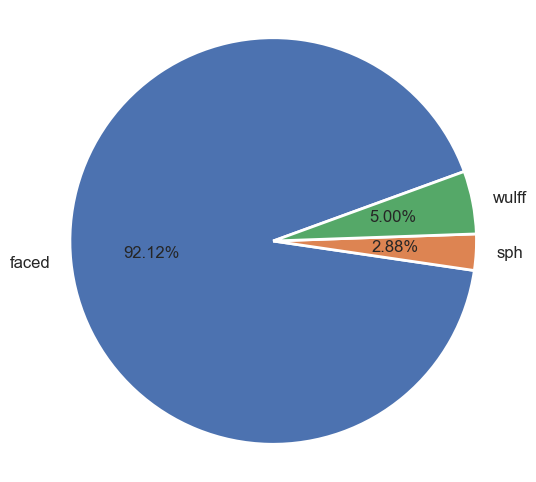

In [7]:
shape_data = NP_data_df['shape'].values
unique_shape, counts_shape = np.unique(shape_data, return_counts=True)

plt.figure(figsize=(6,6))
colors = sns.color_palette(palette="muted", n_colors=3)
plt.pie(counts_shape,labels=unique_shape,
        autopct='%1.2f%%',
        radius=1.1,
        startangle=20,
        textprops={'fontsize':12,},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
        )
plt.savefig('../images/NP_distribution.png',dpi=600)
plt.show()

### Гистограммы распределения НЧ по количеству атомов в их составе для различных «форм» (методов вырезания из фольги) в наборе данных.

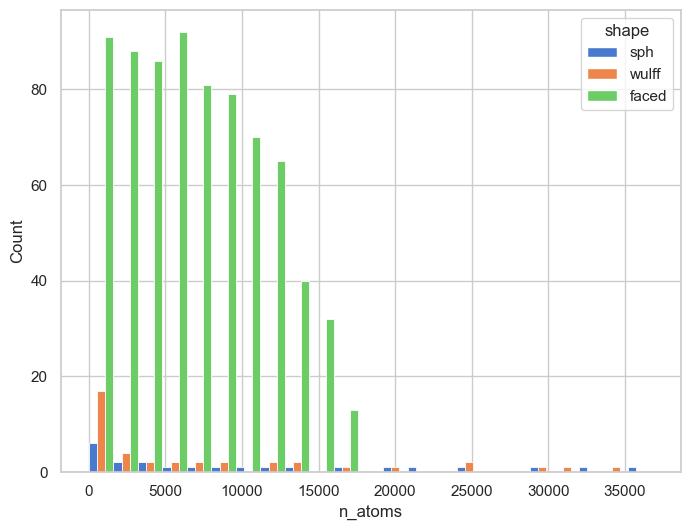

In [8]:
plt.figure(figsize=(8,6))
sns.histplot(data=NP_data_df,
             x='n_atoms',
             hue='shape',
             hue_order=['sph','wulff','faced'],
             stat='count', # frequency, percent, count
             palette='muted',
             multiple='dodge', # fill, stack, layer, dodge
             alpha=0.99,
             # kde=True,
             # log_scale=(True,False)
            )
plt.savefig('../images/NP_distribution_hists.png',dpi=600)
plt.show()

### Графики распределения НЧ по размеру для различных «форм» (методов вырезания из фольги) в наборе данных.

In [9]:
# Создадим новый "вытянутый" DataFrame для удобства визуализации.
df_melted = pd.melt(NP_data_df,
                    id_vars=['shape'],
                    value_vars=['RDF_equil_size', 'Pair_init_size'],    # колонки для объединения
                    var_name='Size_Type',
                    value_name='Size_Value'
                   )
df_melted

,shape,Size_Type,Size_Value
0,sph,RDF_equil_size,14.4300
1,sph,RDF_equil_size,47.1000
2,faced,RDF_equil_size,9.3200
3,faced,RDF_equil_size,12.5400
4,faced,RDF_equil_size,13.1400
...,...,...,...
1595,faced,Pair_init_size,93.7624
1596,faced,Pair_init_size,93.7624
1597,faced,Pair_init_size,93.7624
1598,faced,Pair_init_size,93.7624


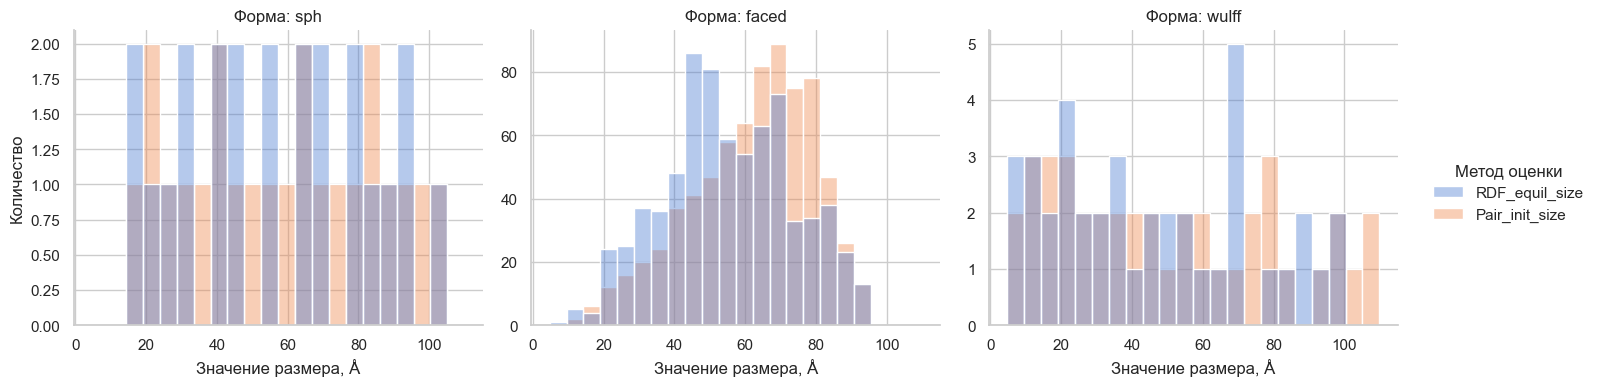

In [10]:
g = sns.displot(data=df_melted,
                x='Size_Value',
                hue='Size_Type',
                col='shape',               # Каждая форма получает свой отдельный график
                kind='hist',
                alpha=0.4,
                multiple='layer',
                height=4,                  # Высота каждого подграфика
                aspect=1.2,                # Пропорции подграфиков
                palette='muted',
                facet_kws={'sharey': False}
               )

g.set_axis_labels("Значение размера, Å", "Количество")
g.set_titles("Форма: {col_name}")
g._legend.set_title("Метод оценки")

plt.savefig('../images/NP_size_distribution_hist.png',dpi=600)
plt.show()

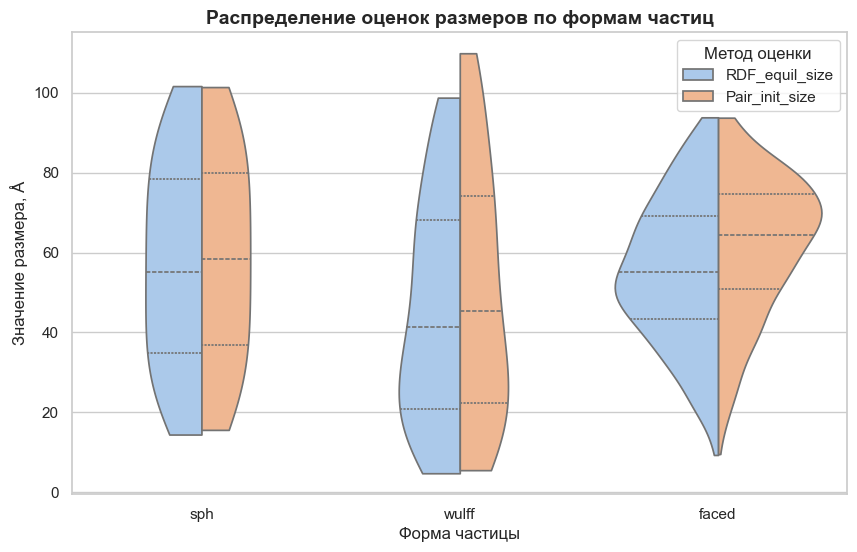

In [11]:
plt.figure(figsize=(10, 6))

sns.violinplot(data=df_melted,
               x='shape',
               y='Size_Value',
               hue='Size_Type',
               order=['sph','wulff','faced'],
               split=True,
               inner='quart',        # Показывает квартили внутри распределения
               palette='pastel',
               cut=0                 # Отключение сглаживания хвостов распределений.
              )

plt.title("Распределение оценок размеров по формам частиц", fontsize=14, fontweight='bold')
plt.xlabel("Форма частицы")
plt.ylabel("Значение размера, Å")
plt.legend(title="Метод оценки")

plt.savefig('../images/NP_size_distribution_violin.png',dpi=600)
plt.show()

### Графики рассеяния для координационных чисел для различных «форм» (методов вырезания из фольги) в зависимости от размера.

In [12]:
# Создадим еще один "вытянутый" DataFrame для удобства визуализации.
df_melted_cn = pd.melt(NP_data_df,
                       id_vars=['shape', 'RDF_equil_size'],                       # Столбцы, которые остаются
                       value_vars=['Equil_CN1', 'Equil_CN2', 'Equil_CN3'],        # Столбцы, которые объединяем
                       var_name='CN_Type',
                       value_name='CN_Value'
                      )
# Уберем строку с нулевыми значениями CN.
df_melted_cn = df_melted_cn.query('CN_Value>0')

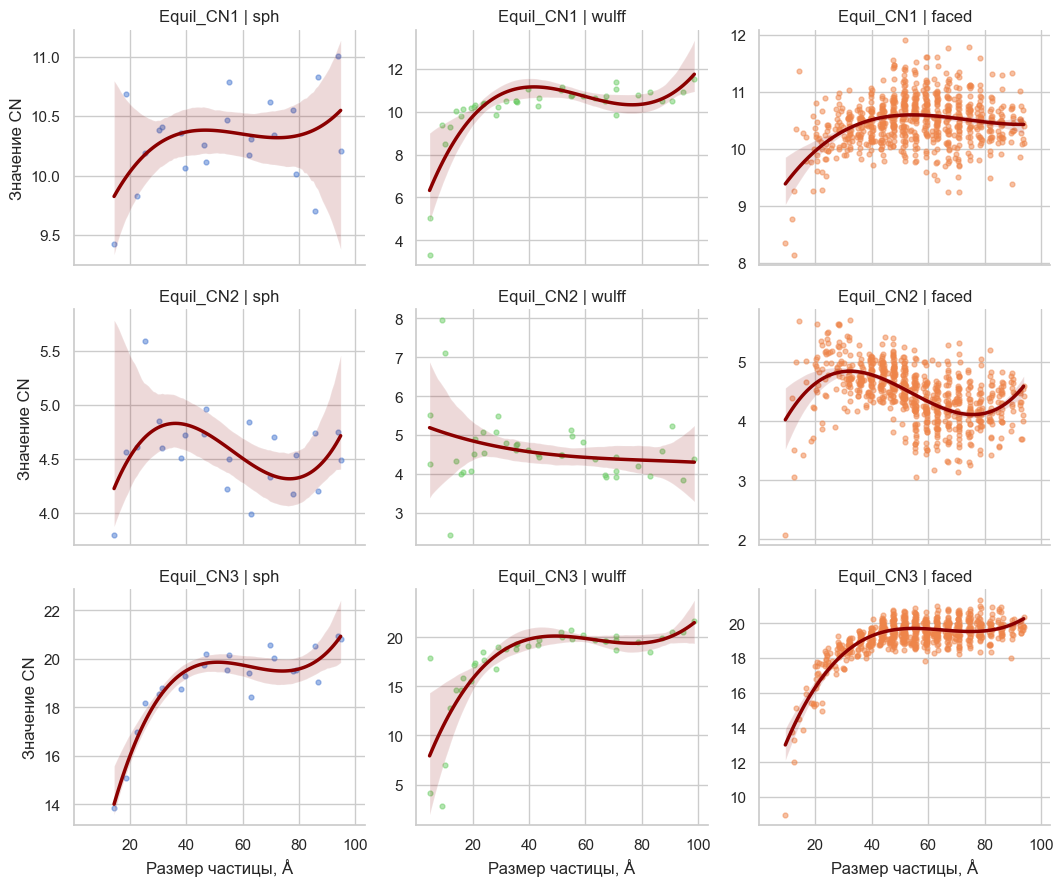

In [13]:
g = sns.lmplot(data=df_melted_cn,
               x='RDF_equil_size',
               y='CN_Value',
               col='shape',
               row='CN_Type',
               hue='shape',
               palette='muted',
               col_order=['sph','wulff','faced'],
    
               # НАСТРОЙКА ПОЛИНОМА:
               order=3,                  # Задает полином 3-го порядка для аппроксимации
               ci=95,                    # Отображать 95% доверительный интервал вокруг линии
    
               # Настройка отображения элементов
               scatter_kws={'alpha': 0.5, 's': 12},
               line_kws={'color': 'darkred', 'lw': 2.5},
    
               height=3,
               aspect=1.2,
               facet_kws={'sharey': False, 'sharex':True}
              )


g.set_axis_labels("Размер частицы, Å", "Значение CN")
g.set_titles(col_template="{col_name}", row_template="{row_name}")

plt.savefig('../images/NP_CN_distribution_different_shape.png',dpi=600)
plt.show()

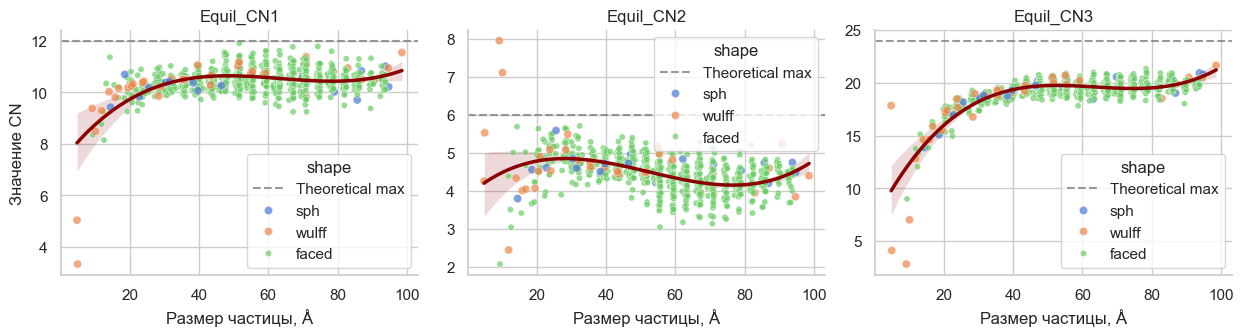

In [14]:
shape_order = ['sph', 'wulff', 'faced']
palette = sns.color_palette("muted", n_colors=3)
sizes = [35,35,20]

color_dict = dict(zip(shape_order, palette))
size_dict = dict(zip(shape_order, sizes))

fcc_max_cn = {'Equil_CN1': 12,
              'Equil_CN2': 6,
              'Equil_CN3': 24
             }

# Линия тренда без точек.
g = sns.lmplot(data=df_melted_cn,
               x='RDF_equil_size',
               y='CN_Value',
               col='CN_Type',
               order=3,                  
               ci=95,                    
               scatter_kws={'s': 0}, # Точки не отрисовываются
               line_kws={'color': 'darkred', 'lw': 2.5},
               height=3.5,
               aspect=1.2,
               facet_kws={'sharey': False, 'sharex': True}
              )

# получим уникальные значения CN_Type в том порядке, в котором их расположил Seaborn
cn_types = df_melted_cn['CN_Type'].unique()

axes_flat = g.axes.flatten()

# Дорисовываем точки.
for i, cn_name in enumerate(cn_types):
    ax = axes_flat[i]

    theoretical_max = fcc_max_cn[cn_name]
    ax.axhline(y=theoretical_max, 
               color='gray', 
               linestyle='--', 
               linewidth=1.5, 
               alpha=0.8,
               label='Theoretical max'
              )
    
    sub_df = df_melted_cn[df_melted_cn['CN_Type'] == cn_name]
    
    sns.scatterplot(data=sub_df,
                    x='RDF_equil_size',
                    y='CN_Value',
                    hue='shape',
                    hue_order=shape_order,
                    palette=color_dict,
                    size='shape',            # Группируем размер по колонке shape
                    size_order=shape_order,  # Задаем порядок
                    sizes=size_dict, 
                    alpha=0.7,
                    ax=ax,
                    legend=True
                   )

g.set_axis_labels("Размер частицы, Å", "Значение CN")
g.set_titles(col_template="{col_name}")

plt.savefig('../images/NP_CN_distribution.png', dpi=600)
plt.show()

### Графики распределений асферичности НЧ по форме

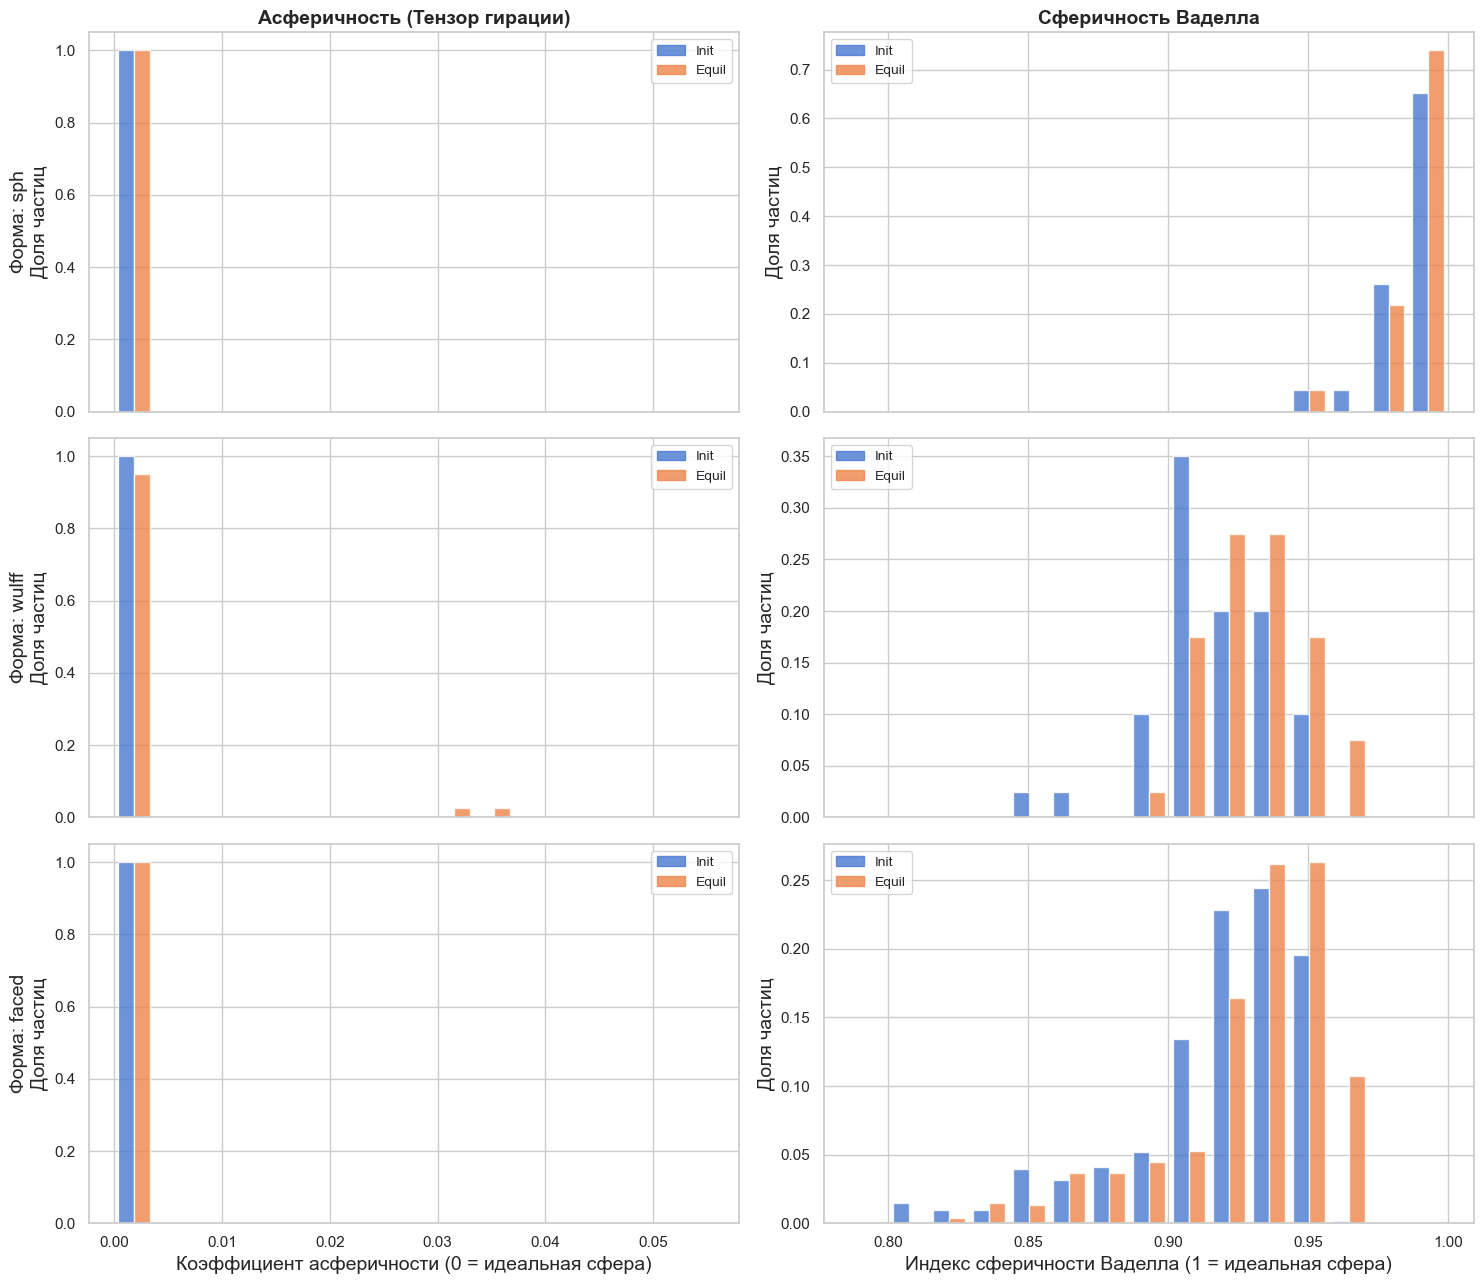

In [15]:
plot_shape_asphericity(NP_data_df, save_path='../images/NP_aspherisity_distribution.png')

## Проверим аномальные структуры с значением CN2>6 (вероятно они же видны на графике асферичности)

In [16]:
NP_data_df[NP_data_df['Equil_CN2']>6]

,NP_index,shape,n_atoms,RDF_equil_size,Pair_init_size,Equil_gyration_asphericity,Equil_Wadell_sphericity,Init_gyration_asphericity,Init_Wadell_sphericity,Equil_CN1,Equil_CN2,Equil_CN3
239,32,wulff,43,9.13,9.5530,0.0356,0.9360,0.0,0.9478,9.37,7.95,2.81
250,33,wulff,55,10.06,11.0308,0.0001,0.9506,0.0,0.9050,8.48,7.11,7.01


Обе структуры вырезаны с помощью Wulff и имеют маленький размер

Гипотеза: 

     ввиду малого размера (43 и 55 атомов) и вероятно высокой угловатостью (wulff)?
     НЧ "сильно" ужимаются и ГЦК симметрия нарушается

Проверка:

    Посмотреть на сами структуры;
    Отрисовать гистограммы распределения парных расстояний.


In [17]:
# Есть 25 НЧ размерами менее 20 ангстрем с разными "формами", и с более выраженными изменениями "асферичности"
# Поэтому вероятно, что столь выраженное нарушение симметрии только для wulff обусловлено случайным совпадением.

tdf = NP_data_df[NP_data_df['RDF_equil_size']<20].copy()
tdf['Asph_dif'] = tdf['Equil_gyration_asphericity']-tdf['Init_gyration_asphericity']
tdf['Sph_dif'] = tdf['Equil_Wadell_sphericity']-tdf['Init_Wadell_sphericity']

tdf.sort_values(by=['Asph_dif','Sph_dif'],ascending=[False,False],inplace=True)
tdf[['NP_index','shape','n_atoms','RDF_equil_size','Pair_init_size','Asph_dif','Sph_dif']]

,NP_index,shape,n_atoms,RDF_equil_size,Pair_init_size,Asph_dif,Sph_dif
239,32,wulff,43,9.13,9.5530,0.0356,-0.0118
228,31,wulff,19,4.91,7.8000,0.0316,0.0633
2,100,faced,43,9.32,9.5530,0.0047,-0.0096
217,30,wulff,13,4.74,5.5154,0.0005,0.0340
3,101,faced,87,12.54,13.5100,0.0004,0.0035
7,105,faced,93,12.34,15.6000,0.0003,0.0247
11,109,faced,297,19.26,19.8862,0.0002,0.0176
250,33,wulff,55,10.06,11.0308,0.0001,0.0456
6,104,faced,171,11.79,18.2926,0.0001,0.0238
261,34,wulff,79,11.84,12.3328,0.0001,0.0220


In [18]:
def analyze_nanoparticle_relaxation(atoms_init: Atoms, atoms_equil: Atoms, title_suffix: str = "", save_path: Union[Path,str] = None):
    """
    Визуализирует структуры НЧ (init и equil) и строит гистограммы 
    распределения всех парных расстояний для оценки влияния релаксации.
    """
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), gridspec_kw={'height_ratios': [1, 1]})

    # Начальная структура
    plot_atoms(atoms_init, axes[0, 0], radii=0.8, rotation='10x,10y,0z', show_unit_cell=1)
    axes[0, 0].set_title(f"Исходная структура (Init) {title_suffix}", fontsize=14, fontweight='bold')
    axes[0, 0].set_axis_off()
    
    # Равновесная структура
    plot_atoms(atoms_equil, axes[0, 1], radii=0.8, rotation='10x,10y,0z', show_unit_cell=1)
    axes[0, 1].set_title(f"Равновесная структура (Equil) {title_suffix}", fontsize=14, fontweight='bold')
    axes[0, 1].set_axis_off()
    
    # Отрисовка гистограмм (из матрицы расстояний берем верхний треугольник сдвинутый над главной диагональю)
    dist_init = atoms_init.get_all_distances()
    dist_init_flat = dist_init[np.triu_indices_from(dist_init, k=1)]
    
    dist_equil = atoms_equil.get_all_distances()
    dist_equil_flat = dist_equil[np.triu_indices_from(dist_equil, k=1)]
    
    bin_width = 0.05  # ширина бина гистограммы (для заметности смещений расстояний)
    
    # Гистограмма для Init
    sns.histplot(x=dist_init_flat, 
                 ax=axes[1, 0], 
                 binwidth=bin_width, 
                 color='blue', 
                 alpha=0.75, 
                 kde=True
                )
    
    axes[1, 0].set_xlabel("Парное расстояние, Å", fontsize=12)
    axes[1, 0].set_ylabel("Count", fontsize=12)
    axes[1, 0].set_title("Распределение расстояний (Init)", fontsize=12)
    
    # Гистограмма для Equil
    sns.histplot(x=dist_equil_flat, 
                 ax=axes[1, 1], 
                 binwidth=bin_width, 
                 color='red', 
                 alpha=0.75, 
                 kde=True
                )
    
    axes[1, 1].set_xlabel("Парное расстояние, Å", fontsize=12)
    axes[1, 1].set_ylabel("Count", fontsize=12)
    axes[1, 1].set_title("Распределение расстояний (Equil)", fontsize=12)
    
    # Настроим одинаковым образом ось X для гистограмм.
    x_min = min(dist_init_flat.min(), dist_equil_flat.min()) - 0.5
    x_max = max(dist_init_flat.max(), dist_equil_flat.max()) + 0.5
    axes[1, 0].set_xlim(x_min, x_max)
    axes[1, 1].set_xlim(x_min, x_max)
    
    plt.suptitle(f"Анализ структурных изменений наночастицы {title_suffix}", fontsize=16, fontweight='bold', y=0.98)

    if save_path:
        plt.savefig(save_path, dpi=600)

    plt.show()

In [19]:
np32_init  = read('../source_data/simdata/32/initial.xyz')
np32_equil = read('../source_data/simdata/32/equil.xyz')

np33_init  = read('../source_data/simdata/33/initial.xyz')
np33_equil = read('../source_data/simdata/33/equil.xyz')

tdf_33 = pd.read_csv('../source_data/simdata/33/scalars.csv')
tdf_32 = pd.read_csv('../source_data/simdata/32/scalars.csv')

In [20]:
tdf_32

,shape,n1,n2,n3,natoms,size,N1,N2,N3,R1,R2,R3,ss2_1,ss2_2,ss2_3
0,wulff,20,0,0,43,9.13,9.37,7.95,2.81,2.701,4.454,4.902,0.006,0.007,0.0105


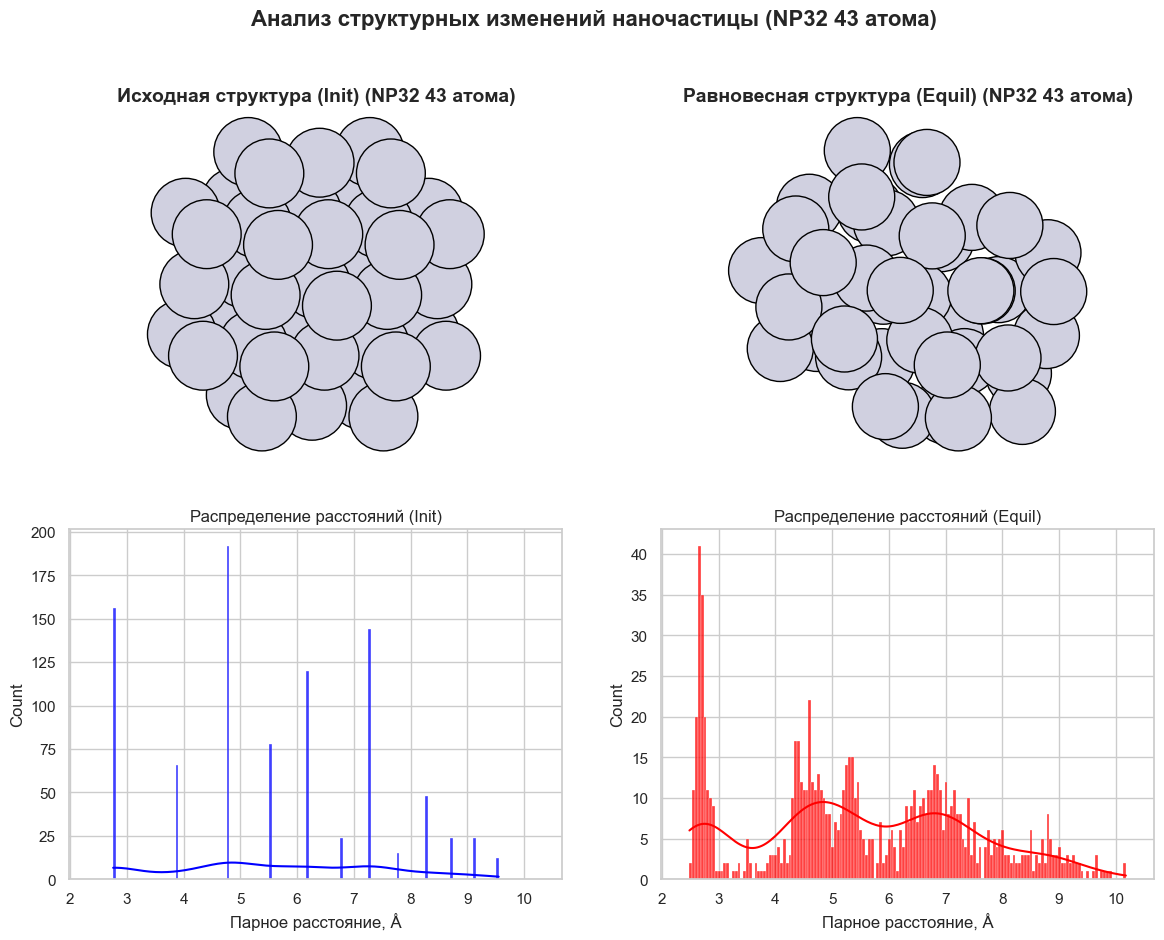

In [21]:
analyze_nanoparticle_relaxation(np32_init, np32_equil, title_suffix="(NP32 43 атома)", save_path='../images/NP32_symmetry breaking.png')

In [22]:
tdf_33

,shape,n1,n2,n3,natoms,size,N1,N2,N3,R1,R2,R3,ss2_1,ss2_2,ss2_3
0,wulff,46,0,0,55,10.06,8.48,7.11,7.01,2.74,3.876,4.609,0.007,0.0054,0.0125


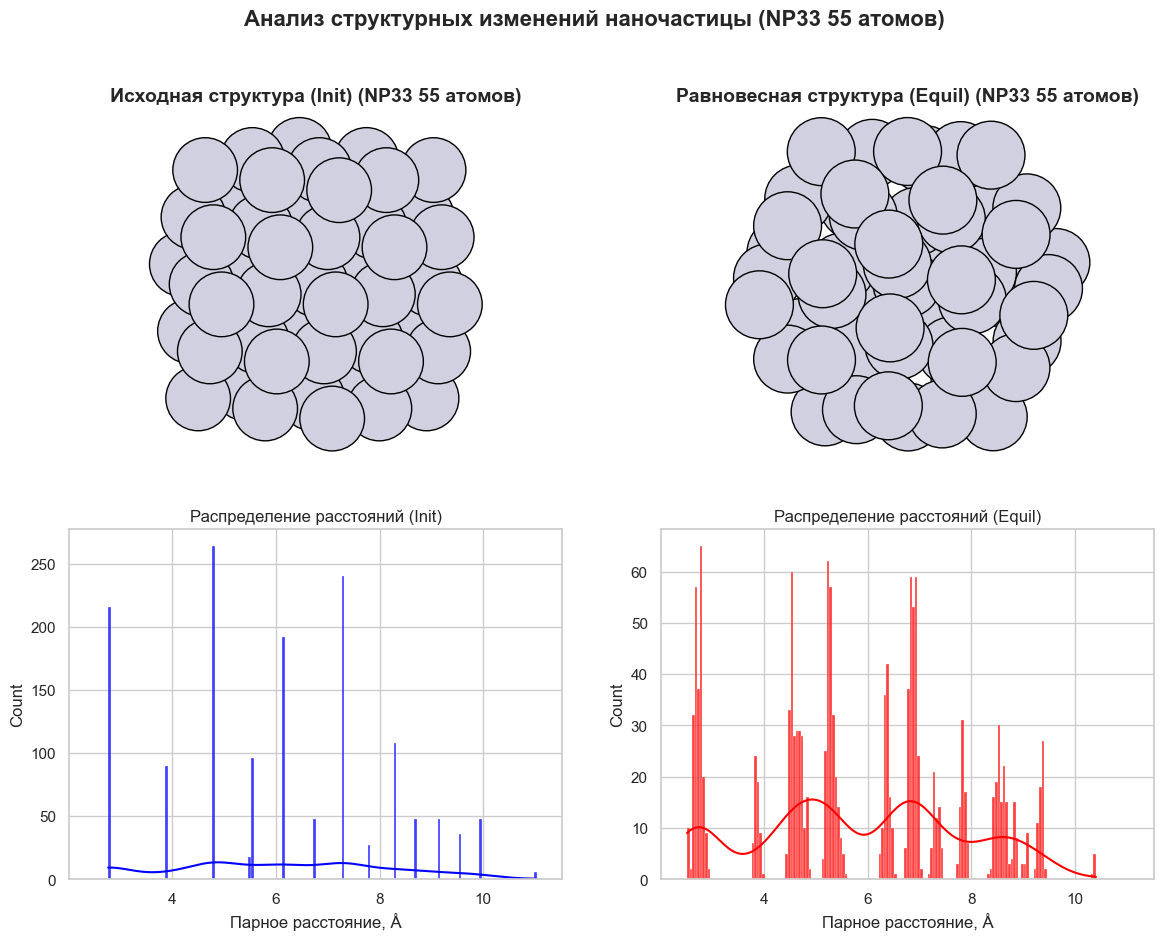

In [23]:
analyze_nanoparticle_relaxation(np33_init, np33_equil, title_suffix="(NP33 55 атомов)", save_path='../images/NP33_symmetry breaking.png')

In [24]:
# Для 32 НЧ наблюдается сильная деформация и размытие границ координационных сфер, что объясняет наблюдаемые результаты
# В случае 33 НЧ симметрия сохраняется намного лучше а границы "малых" сфер не пересекаются.
# Вероятно в процессе релаксации образовался дефект во 2 координационной сфере куда перешел атом из соседней сферы,
# поэтому мы наблюдаем с одной стороны сжатие НЧ (по гистаграмме расстояний), а с другой - просветы в 3D геометрии.